## Viva points

- PCA is **unsupervised** and **linear**. It does not use the labels.
- Components are ordered: PC1 keeps the most variance, then PC2 and so on.
- Always **scale** the data before PCA.
- Benefit: fewer features means faster training and less overfitting. Cost: some information is lost, so the new features are hard to interpret.

Features before PCA: 13
Features after PCA: 2
Accuracy without PCA: 0.9444444444444444
Accuracy with PCA: 0.9722222222222222


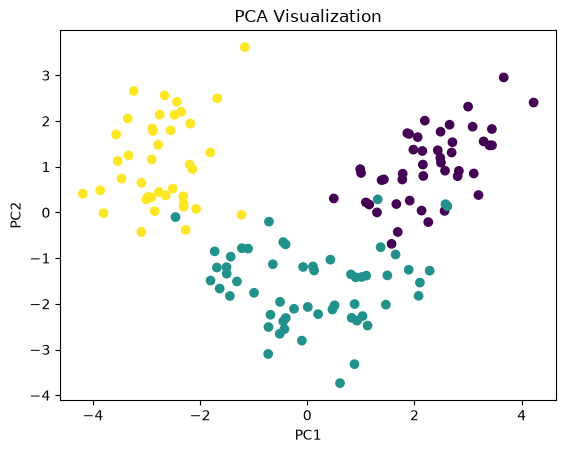

In [2]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = load_wine()
X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Without PCA
m1 = DecisionTreeClassifier(random_state=42)
m1.fit(X_train, y_train)
p1 = m1.predict(X_test)
acc1 = accuracy_score(y_test, p1)

# Apply PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# With PCA
m2 = DecisionTreeClassifier(random_state=42)
m2.fit(X_train_pca, y_train)
p2 = m2.predict(X_test_pca)
acc2 = accuracy_score(y_test, p2)

# Compare
print("Features before PCA:", X.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Accuracy without PCA:", acc1)
print("Accuracy with PCA:", acc2)

# Visualization
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization")
plt.show()